# Seaborn – EDA rápido y gráficos estadísticos

💬 **Qué es:** Seaborn es una librería de alto nivel construida sobre **Matplotlib** y **Pandas** que facilita la creación de gráficos estadísticos con **menos código y mejor estética**.

🎯 **Para qué sirve:** EDA rápido, comparaciones entre variables, análisis por categorías, correlaciones y regresiones.

🔁 **Diferencias con Matplotlib:** Matplotlib es bajo nivel (control fino). Seaborn añade **abstracciones estadísticas** (agregaciones, estimadores, faceteado) y estilos por defecto.

## Configuración y carga de datos

💡 **Idea clave:** Establece tema/estilo y paleta al inicio. Usa `load_dataset` para datasets de ejemplo.

In [24]:
from pathlib import Path
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


sns.set_theme(style="whitegrid")           # Estilo base
sns.set_palette("deep")                    # Paleta por defecto
tips = sns.load_dataset("tips")
penguins = sns.load_dataset("penguins")    # para el bonus EDA final

✅ **Consejo:** Cambia la paleta cuando quieras con `sns.set_palette("pastel")` o por gráfico con `palette="muted"`.

🧩 **Ejercicio:** Cambia a `sns.set_theme(style="darkgrid")` y compara.

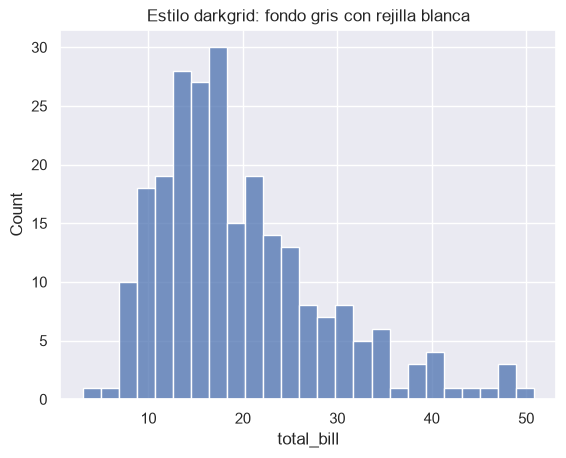

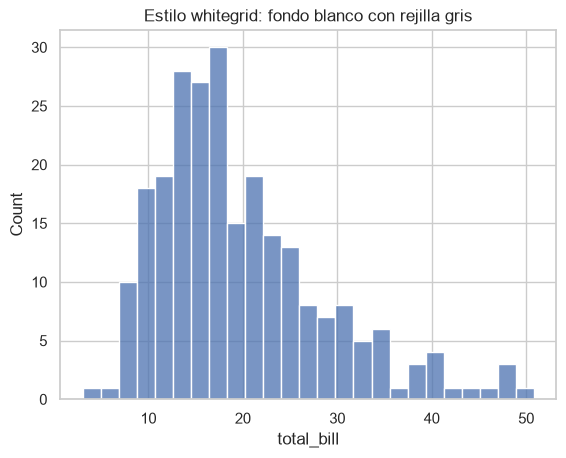

In [25]:
sns.set_theme(style="darkgrid")           # Ejercicio: compara con "whitegrid"
sns.histplot(data=tips, x="total_bill", bins=25)
plt.title("Estilo darkgrid: fondo gris con rejilla blanca")
plt.show()

sns.set_theme(style="whitegrid")          # Volvemos al estilo base para el resto del notebook
sns.histplot(data=tips, x="total_bill", bins=25)
plt.title("Estilo whitegrid: fondo blanco con rejilla gris")
plt.show()

## Gráficos univariantes (distribuciones)

💡 **Selecciona la forma de visualizar una variable** según el contexto (frecuencias, densidad o cuartiles).



### Histograma / KDE (distribución continua)

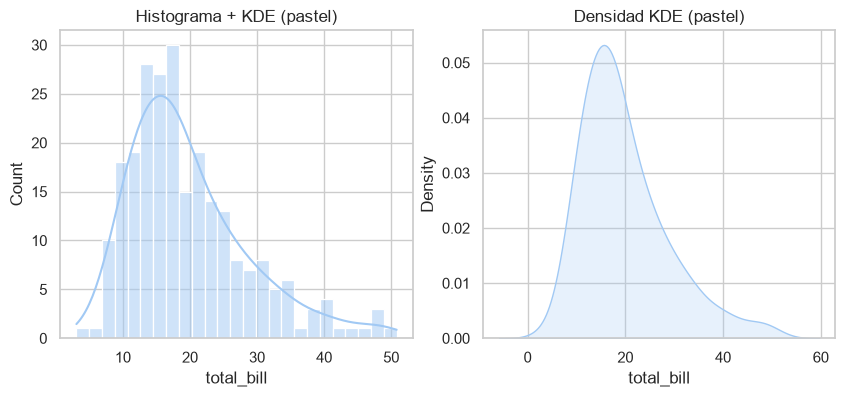

In [26]:
sns.set_palette("pastel")
fig, ax = plt.subplots(1,2, figsize=(10,4))
sns.histplot(data=tips, x="total_bill", bins=25, kde=True, ax=ax[0])
sns.kdeplot(data=tips, x="total_bill", fill=True, ax=ax[1])
ax[0].set_title("Histograma + KDE (pastel)")
ax[1].set_title("Densidad KDE (pastel)")
plt.show()

### Boxplot / Violinplot (distribución por categoría)

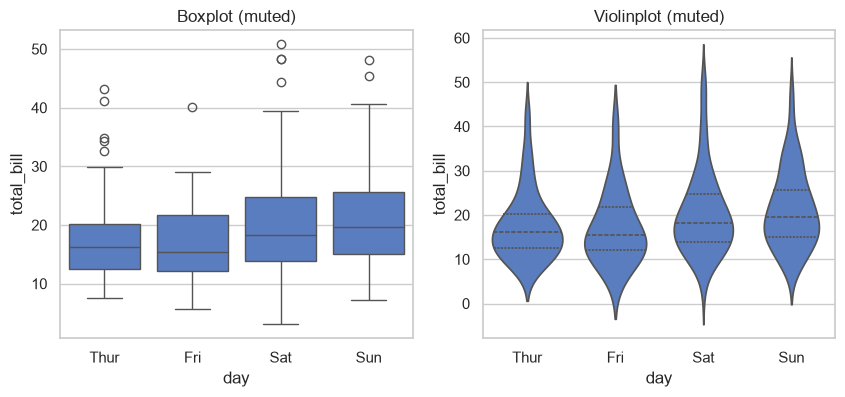

In [27]:
sns.set_palette("muted")
fig, ax = plt.subplots(1,2, figsize=(10,4))
sns.boxplot(data=tips, x="day", y="total_bill", ax=ax[0])
sns.violinplot(data=tips, x="day", y="total_bill", inner="quartile", ax=ax[1])
ax[0].set_title("Boxplot (muted)")
ax[1].set_title("Violinplot (muted)")
plt.show()

✅ **Consejo:** Para muchos puntos, prueba `swarmplot` (muestra distribución discreta sin solaparse).

🧩 **Ejercicio:** Repite el violinplot coloreando por `hue="sex"` y usando `split=True`.

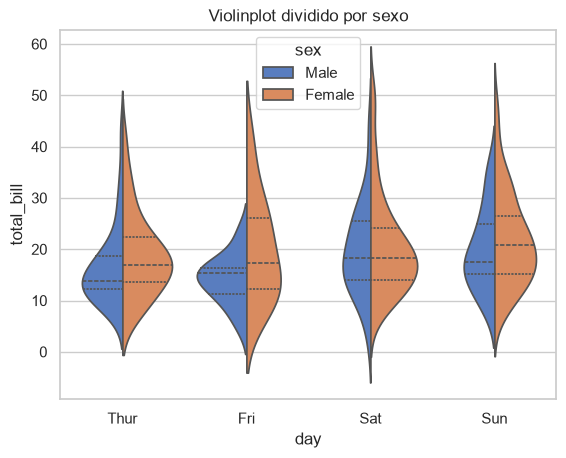

In [28]:
sns.set_palette("muted")
sns.violinplot(data=tips, x="day", y="total_bill", hue="sex",
               split=True, inner="quartile")
plt.title("Violinplot dividido por sexo")
plt.show()

## Gráficos bivariantes y multivariantes

### Dispersión con hue/size/style

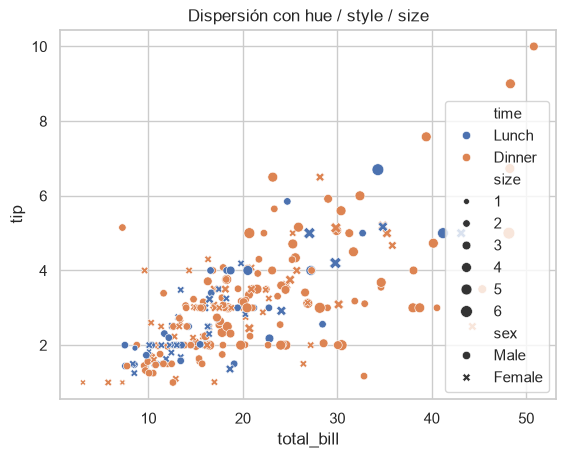

In [4]:
sns.set_palette("deep")
sns.scatterplot(data=tips, x="total_bill", y="tip",
                hue="time", style="sex", size="size")
plt.title("Dispersión con hue / style / size")
plt.show()

### Regresión lineal (lmplot)

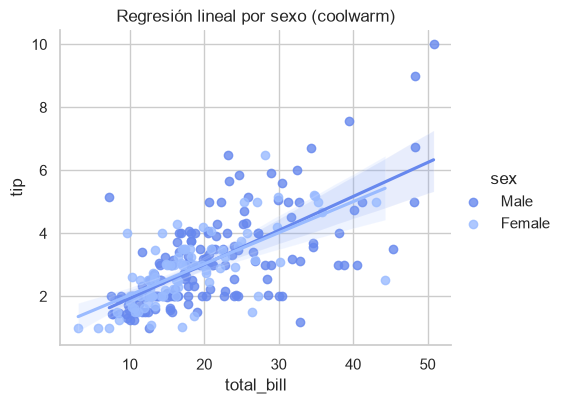

In [5]:
sns.set_palette("coolwarm")
sns.lmplot(data=tips, x="total_bill", y="tip", hue="sex", height=4, aspect=1.2)
plt.title("Regresión lineal por sexo (coolwarm)")
plt.show()

### Matriz de pares (pairplot)

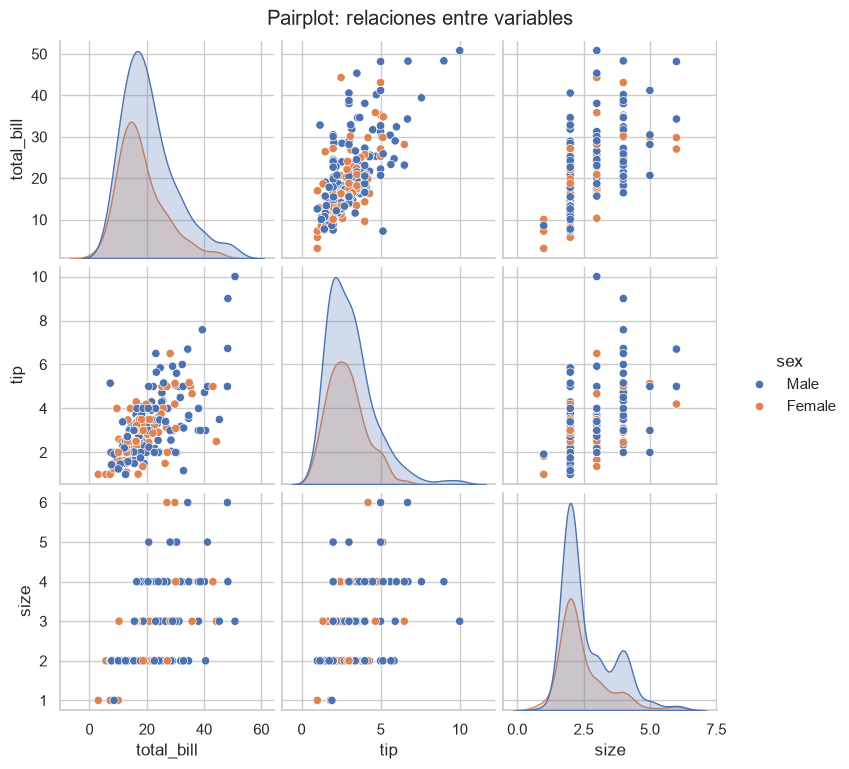

In [6]:
sns.set_palette("deep")
sns.pairplot(data=tips, vars=["total_bill","tip","size"], hue="sex")
plt.suptitle("Pairplot: relaciones entre variables", y=1.02)
plt.show()

### Mapas de calor (correlaciones)

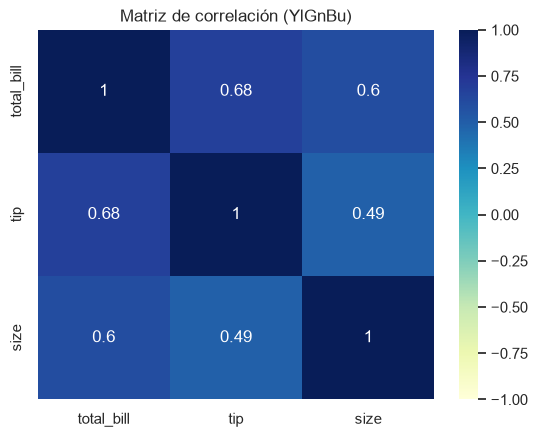

In [7]:
import numpy as np
corr = tips[["total_bill","tip","size"]].corr(numeric_only=True)
sns.heatmap(corr, annot=True, cmap="YlGnBu", vmin=-1, vmax=1, center=0)
plt.title("Matriz de correlación (YlGnBu)")
plt.show()

✅ **Consejo:** Usa `hue` para una tercera variable categórica; `style` y `size` para añadir dimensiones extra.

🧩 **Ejercicio:** Crea `pairplot` de `penguins` con `hue="species"` y comenta diferencias entre especies.

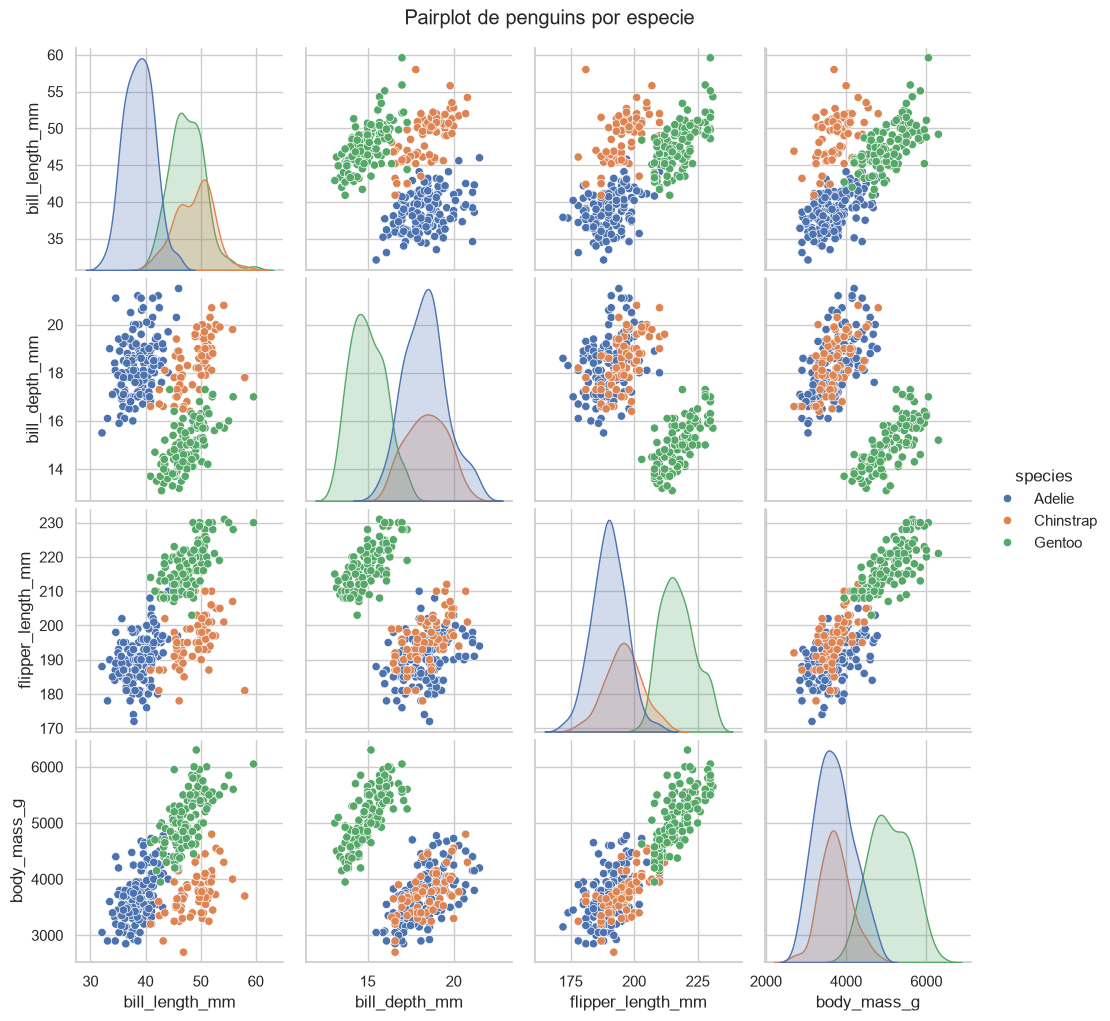

In [29]:
sns.set_palette("deep")
g = sns.pairplot(data=penguins.dropna(), hue="species")
g.figure.suptitle("Pairplot de penguins por especie", y=1.02)
plt.show()

## Gráficos categóricos y agregaciones

💡 **Idea clave:** Seaborn agrega automáticamente (media por defecto) y añade intervalos de confianza.

### Barras (agregación)

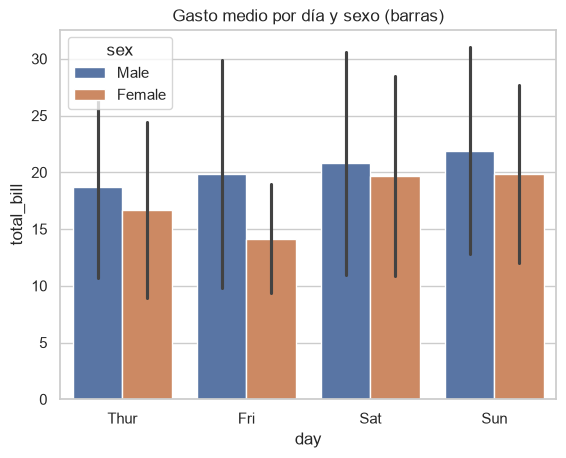

In [8]:
sns.set_palette("deep")
sns.barplot(data=tips, x="day", y="total_bill", hue="sex", estimator="mean", errorbar="sd")
plt.title("Gasto medio por día y sexo (barras)")
plt.show()

### Conteos (frecuencias)

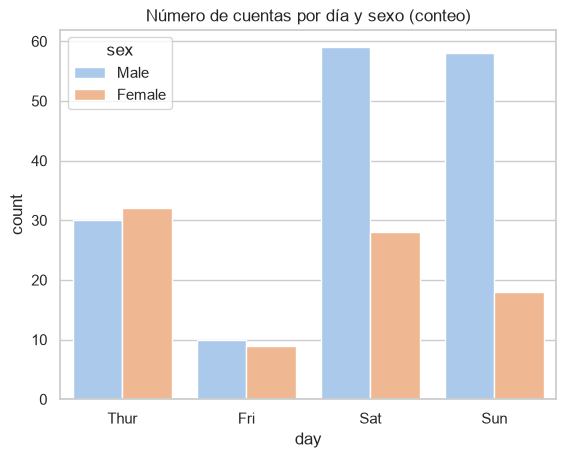

In [9]:
sns.set_palette("pastel")
sns.countplot(data=tips, x="day", hue="sex")
plt.title("Número de cuentas por día y sexo (conteo)")
plt.show()

### catplot (faceteado rápido)

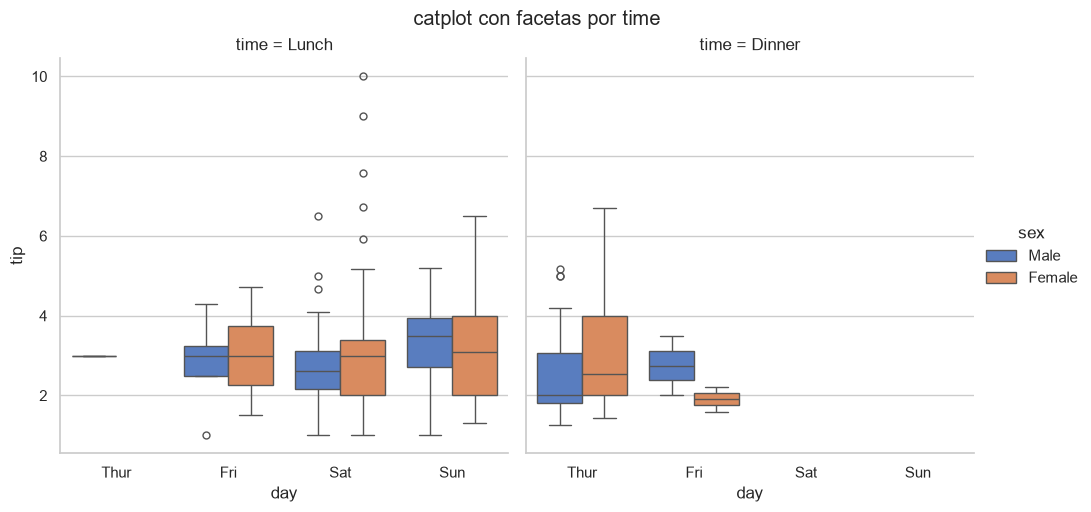

In [10]:
sns.set_palette("muted")
g = sns.catplot(data=tips, x="day", y="tip", hue="sex", kind="box", col="time")
g.fig.suptitle("catplot con facetas por time", y=1.02)
plt.show()

✅ **Consejo:** Cambia el estimador con `estimator=np.median` o quita barras de error con `errorbar=None`.

🧩 **Ejercicio:** Usa `stripplot` encima de `boxplot` (parámetro `dodge=True`) para ver distribución + estadísticos.

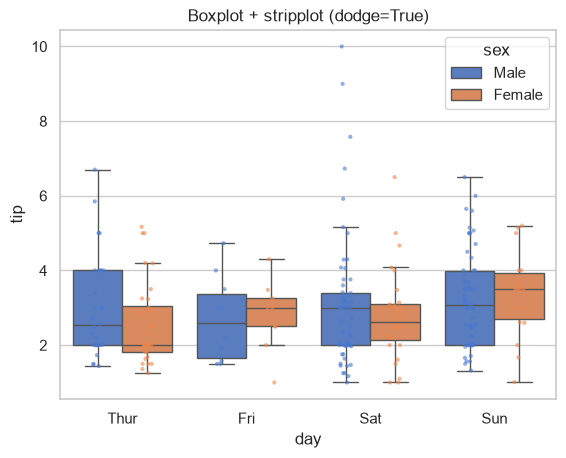

In [30]:
sns.set_palette("muted")
sns.boxplot(data=tips, x="day", y="tip", hue="sex", showfliers=False)
sns.stripplot(data=tips, x="day", y="tip", hue="sex", dodge=True,
              size=3, alpha=0.6, legend=False)
plt.title("Boxplot + stripplot (dodge=True)")
plt.show()

## Control visual básico y personalización ligera

💡 **Seaborn depende de Matplotlib**. Puedes combinar funciones de ambos:

- Tema global: `sns.set_theme(style="whitegrid")`
- Paleta global: `sns.set_palette("deep")` o por gráfico `palette="pastel"`
- Contexto: `sns.set_context("talk")` (aumenta tamaño de fuentes para presentaciones)

C:\Users\ia\AppData\Local\Temp\ipykernel_11564\4285597277.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=tips, x="day", y="tip", palette="pastel",legend=False)


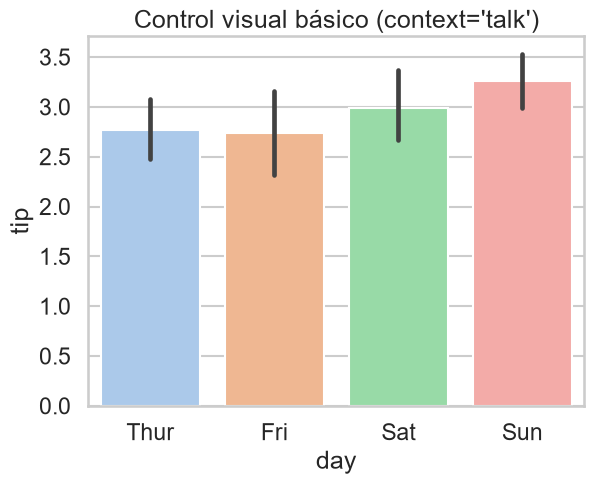

In [11]:
sns.set_theme(style="whitegrid", context="talk")
sns.barplot(data=tips, x="day", y="tip", palette="pastel",legend=False)
plt.title("Control visual básico (context='talk')")
plt.show()

✅ **Consejo:** Para estilos muy personalizados, aplica `plt.style.use(...)` (ver Matplotlib Parte 2).

🧩 **Ejercicio:** Cambia el `context` a `"paper"` y compara tamaños de texto.

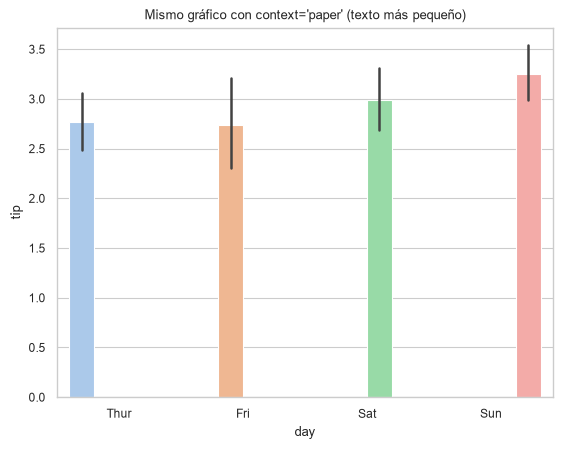

In [31]:
sns.set_theme(style="whitegrid", context="paper")
sns.barplot(data=tips, x="day", y="tip", hue="day", palette="pastel", legend=False)
plt.title("Mismo gráfico con context='paper' (texto más pequeño)")
plt.show()

## Exportación y buenas prácticas

In [12]:
plt.tight_layout()
plt.savefig("seaborn_ejemplo.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

✅ **Buenas prácticas:**

- Usa títulos informativos que expliquen *qué se ve*.
- Limita el número de categorías visibles o usa facetas.
- Ajusta el `context` para presentaciones (`talk`) o informes (`paper`).

🧩 **Ejercicio:** Exporta también a PDF y compara nitidez al hacer zoom.

In [32]:
fig.savefig("seaborn_ejemplo.pdf", bbox_inches="tight")

## Bonus: Mini‑EDA con `penguins` (multivariable)

💡 **Objetivo:** Responder: *¿Cómo varían medidas corporales entre especies? ¿Qué relaciones hay entre longitud de aleta y masa?

In [13]:
sns.set_theme(style="whitegrid")
sns.set_palette("deep")


In [14]:

# 1) Resumen rápido
print(penguins.describe(include="all"))


       species  island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
count      344     344      342.000000     342.000000         342.000000   
unique       3       3             NaN            NaN                NaN   
top     Adelie  Biscoe             NaN            NaN                NaN   
freq       152     168             NaN            NaN                NaN   
mean       NaN     NaN       43.921930      17.151170         200.915205   
std        NaN     NaN        5.459584       1.974793          14.061714   
min        NaN     NaN       32.100000      13.100000         172.000000   
25%        NaN     NaN       39.225000      15.600000         190.000000   
50%        NaN     NaN       44.450000      17.300000         197.000000   
75%        NaN     NaN       48.500000      18.700000         213.000000   
max        NaN     NaN       59.600000      21.500000         231.000000   

        body_mass_g   sex  
count    342.000000   333  
unique          NaN     2  
top

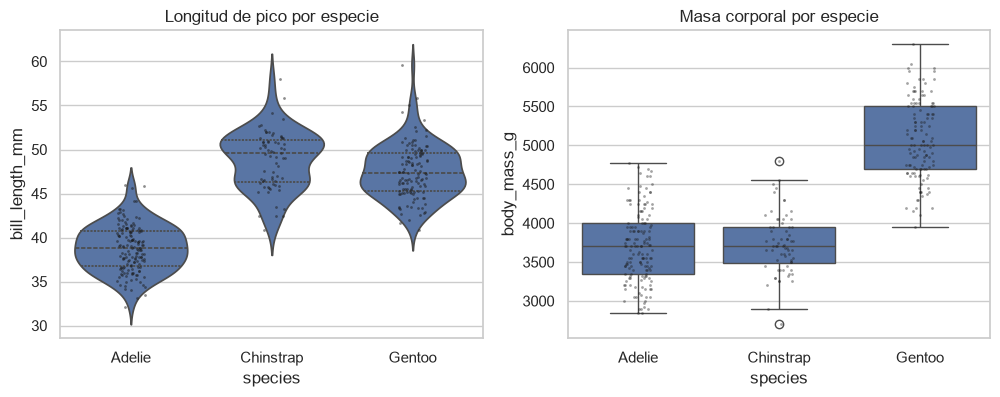

In [15]:

# 2) Distribución por especie (violin + strip)
fig, ax = plt.subplots(1,2, figsize=(12,4))
sns.violinplot(data=penguins, x="species", y="bill_length_mm", inner="quartile", ax=ax[0])
sns.stripplot(data=penguins, x="species", y="bill_length_mm", ax=ax[0], color="k", size=2, alpha=0.5)
ax[0].set_title("Longitud de pico por especie")

sns.boxplot(data=penguins, x="species", y="body_mass_g", ax=ax[1])
sns.stripplot(data=penguins, x="species", y="body_mass_g", color="k", size=2, alpha=0.4, ax=ax[1])
ax[1].set_title("Masa corporal por especie")
plt.show()


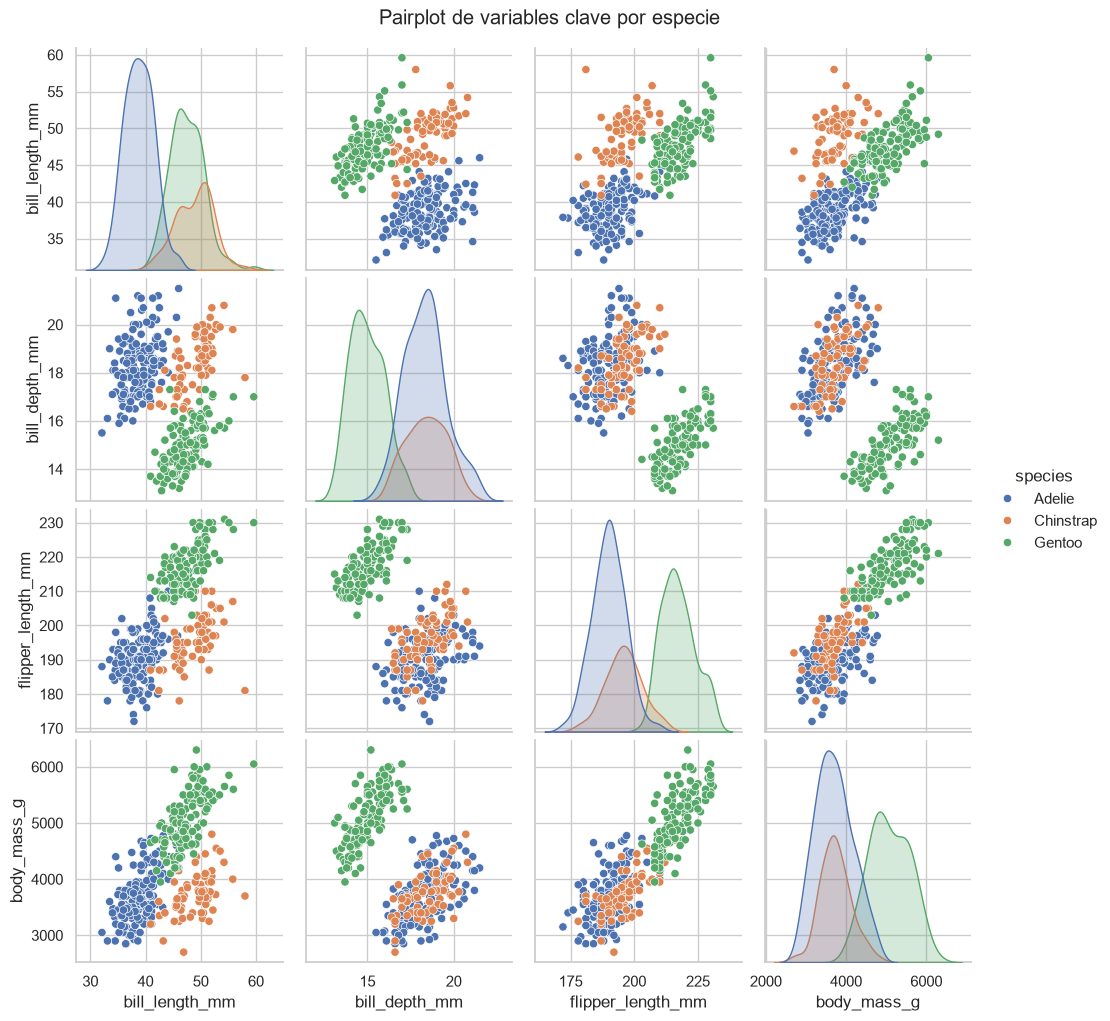

In [ ]:

# 3) Relaciones multivariantes
sns.pairplot(data=penguins, vars=["bill_length_mm","bill_depth_mm","flipper_length_mm","body_mass_g"], hue="species")
plt.suptitle("Pairplot de variables clave por especie", y=1.02)
plt.show()


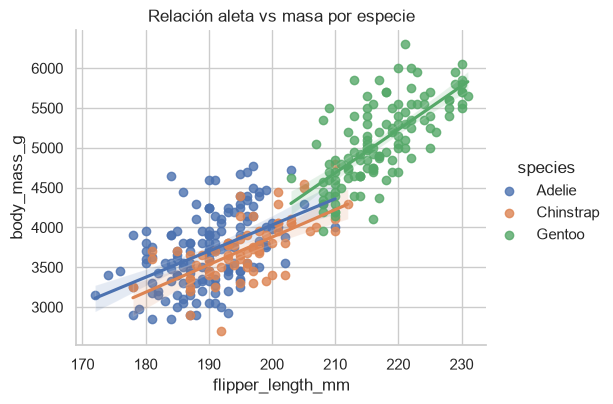

In [17]:

# 4) Regresión y relación clave
sns.lmplot(data=penguins, x="flipper_length_mm", y="body_mass_g", hue="species", height=4, aspect=1.3)
plt.title("Relación aleta vs masa por especie")
plt.show()


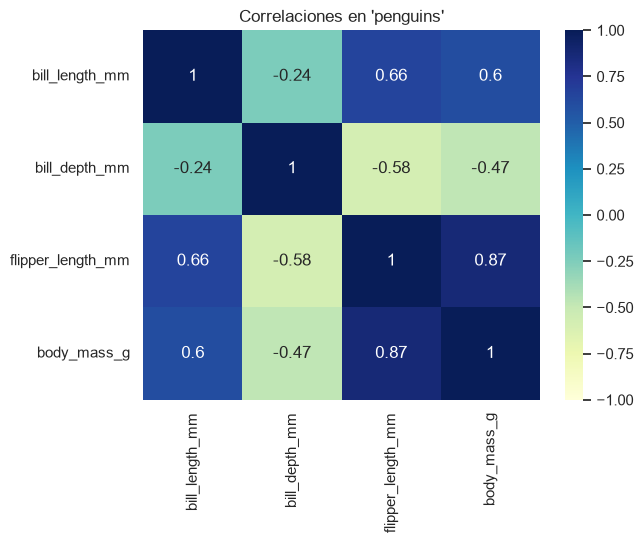

In [18]:

# 5) Correlaciones (numéricas)
corr = penguins[["bill_length_mm","bill_depth_mm","flipper_length_mm","body_mass_g"]].corr(numeric_only=True)
sns.heatmap(corr, annot=True, cmap="YlGnBu", vmin=-1, vmax=1, center=0)
plt.title("Correlaciones en 'penguins'")
plt.show()

✅ **Conclusiones (ejemplo):**

- *Gentoo* tiende a mayor masa y aletas más largas; *Adelie* menor masa.
- Fuerte relación positiva entre **longitud de aleta** y **masa corporal**.

🧩 **Ejercicio final:** Añade `style="sex"` en la regresión para ver diferencias por sexo dentro de cada especie.

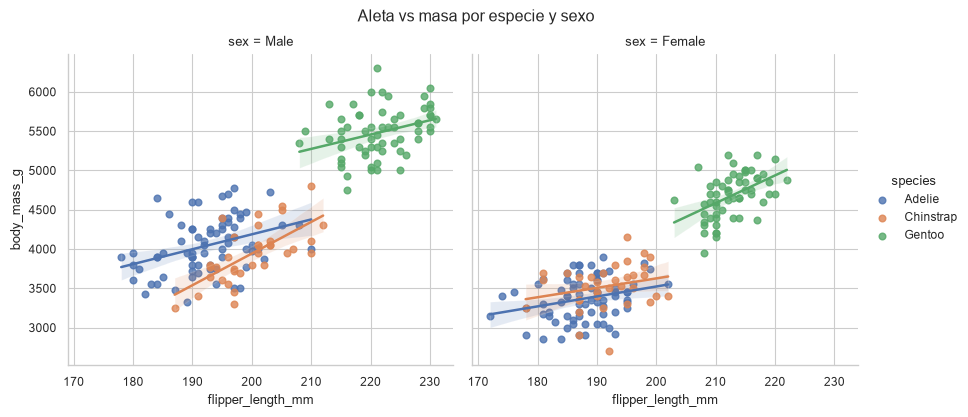

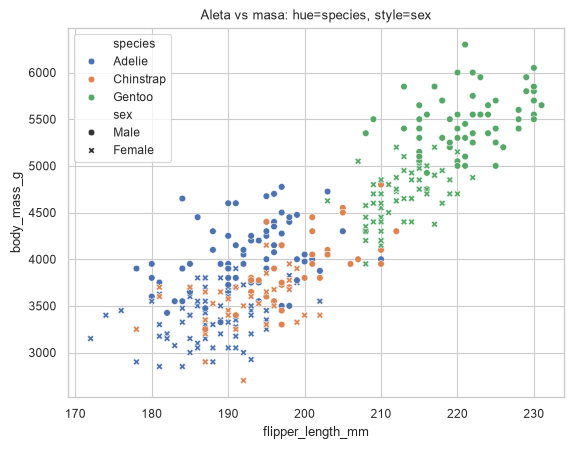

In [33]:
# lmplot no tiene `style`; alternativas: col="sex" (facetas) o markers=[...]
g = sns.lmplot(data=penguins, x="flipper_length_mm", y="body_mass_g",
               hue="species", col="sex", height=4, aspect=1.1)
g.figure.suptitle("Aleta vs masa por especie y sexo", y=1.03)
plt.show()

# Versión con un solo panel: sexo con distinto marcador
sns.scatterplot(data=penguins, x="flipper_length_mm", y="body_mass_g",
                hue="species", style="sex")
plt.title("Aleta vs masa: hue=species, style=sex")
plt.show()

📘 **Resumen rápido:**

- Seaborn simplifica EDA con funciones de alto nivel y buenas estéticas por defecto.
- Usa `hue`, `col/row` (facetas) y `pairplot` para relaciones multivariantes.
- Cambia `palette`, `style`, `context` según el medio (pantalla vs. papel).